# PROJECT TASK – WEEK 8
## Aspect-Based Sentiment Analysis (ABSA) Ulasan Hotel dengan LLM
**Divisi Data Analyst – Vinix7 (PT. Vinix Seven Aurum)**

| Identitas | |
|---|---|
| **Nama Kelompok** | *(isi di sini)* |
| **Anggota** | *(isi di sini)* |

**Latar belakang:** Rating klien Vinix7 di OTA (Agoda, Booking.com, Traveloka) stagnan, dan manajemen belum tahu bagian layanan mana yang bermasalah. Notebook ini membedah teks ulasan per aspek layanan (ABSA) memakai kerangka teori dari riset perhotelan dan otomasi LLM API, lalu mengaitkannya dengan rating bintang untuk menghasilkan insight operasional.

| Bagian | Isi |
|---|---|
| **Task 1** | Riset literatur & penentuan aspek |
| **Task 2** | Setup Google Colab, koneksi API LLM, loading data, mekanisme pemrosesan teks |
| **Task 3** | Custom prompt engineering, looping API, hasil ke DataFrame Pandas |
| **Task 4** | Visualisasi sentimen per aspek, visualisasi silang dengan rating bintang, kesimpulan B-I-A |

> Jalankan sel dari atas ke bawah (*Runtime → Run all*) setelah menyiapkan API key dan file data (lihat Task 2).

---
# TASK 1 – Riset Literatur & Penentuan Aspek

**Rujukan utama**

Alaan, Y. (2016). *Pengaruh Service Quality (Tangible, Empathy, Reliability, Responsiveness dan Assurance) terhadap Customer Satisfaction: Penelitian pada Hotel Serela Bandung.* Jurnal Manajemen, Vol. 15, No. 2, hlm. 255–270. Fakultas Ekonomi, Universitas Kristen Maranatha.

Jurnal ini memakai model **SERVQUAL** (Parasuraman, Zeithaml & Berry, 1988), yang mengukur kualitas layanan melalui lima dimensi. Penelitian dilakukan dengan survei terhadap 100 tamu Hotel Serela Bandung dan dianalisis dengan regresi linier berganda.

**Temuan jurnal (Abstrak & Tabel 6)**
- Kualitas layanan secara simultan berpengaruh terhadap kepuasan pelanggan sebesar **35,80%**.
- **Tangible** (sig 0,001; pengaruh 30,25%) dan **Reliability** (sig 0,011; pengaruh 26,41%) berpengaruh signifikan.
- Responsiveness, Assurance, dan Empathy tidak berpengaruh signifikan. Penulis menjelaskan bahwa ketiganya berkaitan dengan *human capital* dan pelayanan staf yang belum dirasakan tamu.

**Aspek yang dipilih: 5 dimensi SERVQUAL**

| Aspek | Definisi (jurnal) | Contoh indikator (Tabel 1 jurnal) |
|---|---|---|
| **Tangible** | Penampilan fasilitas fisik, peralatan, pegawai, dan material | Furnitur modern & nyaman, dekorasi menarik, fasilitas up-to-date, hotel bersih |
| **Reliability** | Kemampuan memberikan jasa yang dijanjikan secara handal dan akurat | Reservasi diverifikasi akurat, check-in/out tidak lama, sistem reservasi mudah, transportasi tersedia |
| **Responsiveness** | Kesadaran dan keinginan membantu pelanggan serta memberikan jasa dengan cepat | Perhatian dan ketepatan saat menangani permintaan, pertanyaan, dan keluhan |
| **Assurance** | Pengetahuan, sopan santun, dan kemampuan karyawan menumbuhkan keyakinan | Staf sopan, ramah, dan menumbuhkan rasa percaya |
| **Empathy** | Kepedulian dan perhatian pribadi kepada pelanggan | Cepat meminta maaf saat ada kesalahan, mendengarkan keluhan, memahami kebutuhan tamu |

**Alasan pemilihan:** SERVQUAL adalah kerangka kualitas layanan yang paling banyak dirujuk, dan jurnal ini menerapkannya langsung pada hotel di Indonesia. Kelima dimensinya juga muncul di ulasan klien (misalnya kamar bau, check-in lama, staf jutek). Temuan jurnal (Tangible & Reliability paling berpengaruh) dipakai sebagai hipotesis pembanding di Task 4.

In [2]:
# Definisi operasional aspek: dipakai langsung di dalam prompt (Task 3)
ASPEK = {
    "Tangible": "Bukti fisik: kondisi kamar, kasur, AC, kamar mandi/air panas, wifi, kebersihan, bau, nyamuk, "
                "kebisingan/kedap suara, kolam renang, parkir, bangunan, dekorasi, view, serta kualitas & variasi "
                "makanan/sarapan.",
    "Reliability": "Keandalan: layanan sesuai yang dijanjikan dan akurat, yaitu reservasi tepat, kesesuaian kamar "
                   "dengan foto/deskripsi listing, lama proses check-in/check-out, ketersediaan transportasi, "
                   "tagihan bebas kesalahan.",
    "Responsiveness": "Daya tanggap: kesigapan dan kecepatan staf menanggapi permintaan, pertanyaan, dan keluhan "
                      "tamu; termasuk penilaian 'pelayanan' secara umum tanpa detail.",
    "Assurance": "Jaminan: sikap dan kompetensi staf, yaitu ramah/jutek, sopan, pengetahuan, kemampuan bahasa, "
                 "kemampuan menumbuhkan rasa percaya dan aman.",
    "Empathy": "Empati: perhatian personal dan inisiatif di luar permintaan, mendengarkan keluhan, meminta maaf "
               "saat ada kesalahan, memahami kebutuhan khusus tamu.",
}
ASPEK_VALID = list(ASPEK)
SENTIMEN = ["Positif", "Netral", "Negatif"]

import pandas as pd
pd.set_option("display.max_colwidth", 150)
display(pd.DataFrame({"Aspek": ASPEK.keys(), "Definisi operasional untuk LLM": ASPEK.values()}))

,Aspek,Definisi operasional untuk LLM
0,Tangible,"Bukti fisik: kondisi kamar, kasur, AC, kamar mandi/air panas, wifi, kebersihan, bau, nyamuk, kebisingan/kedap suara, kolam renang, parkir, banguna..."
1,Reliability,"Keandalan: layanan sesuai yang dijanjikan dan akurat, yaitu reservasi tepat, kesesuaian kamar dengan foto/deskripsi listing, lama proses check-in/..."
2,Responsiveness,"Daya tanggap: kesigapan dan kecepatan staf menanggapi permintaan, pertanyaan, dan keluhan tamu; termasuk penilaian 'pelayanan' secara umum tanpa d..."
3,Assurance,"Jaminan: sikap dan kompetensi staf, yaitu ramah/jutek, sopan, pengetahuan, kemampuan bahasa, kemampuan menumbuhkan rasa percaya dan aman."
4,Empathy,"Empati: perhatian personal dan inisiatif di luar permintaan, mendengarkan keluhan, meminta maaf saat ada kesalahan, memahami kebutuhan khusus tamu."


---
# TASK 2 – Setup & Otomatisasi (Google Colab)

**Platform LLM:** notebook ini mendukung dua provider yang sama-sama kompatibel dengan format OpenAI, sehingga cukup memakai satu library (`openai`) dengan `base_url` berbeda:

| Provider | Model | Biaya | Secret di Colab | Awalan key |
|---|---|---|---|---|
| **Groq Cloud** (console.groq.com) | Model open-weight, misalnya GPT-OSS 120B / Llama 3.3 70B, dijalankan di chip LPU yang sangat cepat | Ada kuota gratis | `GROQ_API_KEY` | `gsk_` |
| **xAI – Grok** (console.x.ai) | Model Grok buatan xAI | Berbayar (perlu kredit di akun) | `XAI_API_KEY` | `xai-` |

Provider dideteksi **otomatis** dari Secret dan awalan API key, jadi cukup simpan satu key. Kedua provider mendukung *JSON mode* sehingga keluaran model bisa langsung di-parse ke DataFrame. *(Di laporan, jelaskan provider yang benar-benar Anda pakai; namanya dicetak oleh sel 2.2.)*

**Persiapan sebelum menjalankan:**
1. Buat API key: Groq di [console.groq.com/keys](https://console.groq.com/keys), atau Grok di [console.x.ai](https://console.x.ai) (menu *API Keys*).
2. Di Colab, klik ikon **🔑 Secrets** di sidebar kiri → *Add new secret* → Name: `GROQ_API_KEY` (untuk Groq) atau `XAI_API_KEY` (untuk Grok), Value: API key Anda → aktifkan **Notebook access**. Dengan cara ini key tidak pernah tertulis di kode.
3. Upload `client_hotel_review.csv` ke panel *Files* (jika lupa, sel loading data akan memunculkan tombol upload).

### 2.1 Instalasi & import library

In [3]:
!pip install -q -U openai

In [4]:
import os, re, json, time, html
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from openai import OpenAI

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("grafik", exist_ok=True)

### 2.2 Koneksi ke API LLM

In [5]:
from google.colab import userdata

PROVIDER_PILIHAN = "auto"   # "auto", "groq", atau "xai"

PROVIDER_INFO = {
    "groq": {"nama": "Groq Cloud", "base_url": "https://api.groq.com/openai/v1", "secret": "GROQ_API_KEY",
             "awalan": "gsk_", "jeda": 3.0,
             "kandidat": ["openai/gpt-oss-120b", "llama-3.3-70b-versatile", "openai/gpt-oss-20b"]},
    "xai": {"nama": "xAI (Grok)", "base_url": "https://api.x.ai/v1", "secret": "XAI_API_KEY",
            "awalan": "xai-", "jeda": 1.0,
            "kandidat": ["grok-4-fast-non-reasoning", "grok-3-mini"]},
}


def baca_secret(nama):
    try:
        nilai = userdata.get(nama)
        return nilai.strip() if nilai else None
    except Exception:
        return None


# 1) Cari API key di Secrets, lalu tentukan provider dari awalan key
urutan = [PROVIDER_PILIHAN] if PROVIDER_PILIHAN in PROVIDER_INFO else list(PROVIDER_INFO)
PROVIDER, API_KEY = None, None
for p in urutan:
    key = baca_secret(PROVIDER_INFO[p]["secret"])
    if key:
        API_KEY = key
        PROVIDER = next((q for q, i in PROVIDER_INFO.items() if key.startswith(i["awalan"])), p)
        if PROVIDER != p:
            print(f"Catatan: key di Secret '{PROVIDER_INFO[p]['secret']}' ternyata key {PROVIDER_INFO[PROVIDER]['nama']}.")
        break
if API_KEY is None:
    raise ValueError("API key tidak ditemukan. Buat Secret GROQ_API_KEY (Groq) atau XAI_API_KEY (Grok/xAI), "
                     "lalu aktifkan 'Notebook access'.")

INFO = PROVIDER_INFO[PROVIDER]
client = OpenAI(api_key=API_KEY, base_url=INFO["base_url"])
print("Provider:", INFO["nama"])

# 2) Susun kandidat model dari daftar model yang aktif di akun
try:
    model_tersedia = [m.id for m in client.models.list().data]
except Exception as e:
    print("Gagal mengambil daftar model:", str(e)[:150])
    model_tersedia = []

kandidat = [m for m in INFO["kandidat"] if m in model_tersedia]
if PROVIDER == "xai":
    lain = [m for m in model_tersedia if m.startswith("grok")
            and not re.search(r"image|vision|imagine|video|tts|voice|embed", m)]
    lain = sorted(lain, key=lambda m: (0 if "fast" in m else 1 if "mini" in m else 2, m))
    kandidat += [m for m in lain if m not in kandidat]
if not kandidat:
    kandidat = INFO["kandidat"]

# 3) Coba kandidat satu per satu; pakai yang pertama berhasil
LLM_MODEL = None
for m in kandidat[:6]:
    try:
        client.chat.completions.create(model=m, messages=[{"role": "user", "content": "Balas satu kata: OK"}])
        LLM_MODEL = m
        break
    except Exception as e:
        kode = getattr(e, "status_code", None)
        print(f"  {m} tidak bisa dipakai ({kode}): {str(e)[:150]}")
        if kode == 401:
            raise RuntimeError("API key tidak valid. Buat ulang key, lalu perbarui Secret.")
        if kode == 403 and PROVIDER == "xai":
            raise RuntimeError("Akun xAI belum punya kredit/izin. Isi kredit di console.x.ai atau pakai Groq (gratis).")

if LLM_MODEL is None:
    print("Model yang aktif di akun Anda:", model_tersedia)
    raise RuntimeError("Isi INFO['kandidat'] dengan salah satu model di atas, lalu jalankan ulang sel ini.")

# Model GPT-OSS di Groq: penalaran 'low' agar hemat token (kuota token per menit lebih awet)
EKSTRA = {"extra_body": {"reasoning_effort": "low"}} if LLM_MODEL.startswith("openai/gpt-oss") else {}
print("Model yang dipakai:", LLM_MODEL)

tes = client.chat.completions.create(
    model=LLM_MODEL, temperature=0, **EKSTRA,
    messages=[{"role": "user", "content": "Jelaskan dalam satu kalimat apa itu Aspect-Based Sentiment Analysis."}],
)
print("Uji koneksi:", tes.choices[0].message.content)

ValueError: API key tidak ditemukan. Buat Secret GROQ_API_KEY (Groq) atau XAI_API_KEY (Grok/xAI), lalu aktifkan 'Notebook access'.

### 2.3 Loading data

In [ ]:
NAMA_FILE = "client_hotel_review.csv"

if not os.path.exists(NAMA_FILE):
    try:
        from google.colab import files
        print(f"'{NAMA_FILE}' belum ada. Silakan upload:")
        files.upload()
    except ImportError:
        pass

df_raw = pd.read_csv(NAMA_FILE)
print(f"Dataset dimuat: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom → {list(df_raw.columns)}")
display(df_raw.head())

'client_hotel_review.csv' belum ada. Silakan upload:


Saving client_hotel_review.csv to client_hotel_review.csv
Dataset dimuat: 187 baris, 4 kolom → ['Tanggal', 'Platform', 'Rating', 'Review']


,Tanggal,Platform,Rating,Review
0,2026-04-10,agoda.com,5,"Friendly staff, but the wifi connection was terrible."
1,02-03-2026,Agoda,8.0 / 10,"kamar luas, view bagus. proses checkin juga sat set ga pake lama. recommended! <br><br>"
2,16/03/2026,agoda.com,3/10,overprice! ga sesuai foto. kamarnya sempit bgt sumpek.
3,2026-03-09,Agoda,2,Staff barely speaks English. Breakfast was awful.
4,2026-04-13,Traveloka,4.0,"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya. <br><br>"


### 2.4 Audit & cleaning data

Data mentah memiliki masalah kualitas yang harus dibereskan sebelum diproses:

| Masalah | Contoh | Penanganan |
|---|---|---|
| Nama platform tidak seragam | `agoda.com`, `Agoda`, `tvlk`, `Booking` | Dipetakan ke 3 nama baku |
| Skala rating campur | `8.0 / 10`, `3/5`, `2/10`, angka polos | Dinormalisasi ke **skala 1–5**. Angka polos mengikuti skala platform (Traveloka /5, Agoda & Booking.com /10) |
| Format tanggal beragam | `2026-04-10`, `02-03-2026`, `16/03/2026`, `March 13, 2026` | Diparsing dengan beberapa format |
| Tag HTML & catatan sistem | `<br><br>`, `<i>...</i>`, `[Translated by System]` | Dihapus |

In [ ]:
print("Variasi penulisan platform :", df_raw["Platform"].value_counts().to_dict())
print("Contoh format rating       :", df_raw["Rating"].drop_duplicates().head(12).tolist())
print("Contoh format tanggal      :", df_raw["Tanggal"].drop_duplicates().sample(8, random_state=1).tolist())
print("Ulasan mengandung tag HTML :", df_raw["Review"].str.contains(r"<[^>]+>", regex=True).sum())
print("Ulasan '[Translated by System]':", df_raw["Review"].str.contains("Translated by System", case=False).sum())
print("Nilai kosong per kolom     :", df_raw.isna().sum().to_dict())

Variasi penulisan platform : {'Booking.com': 39, 'tvlk': 36, 'Traveloka': 34, 'Booking': 27, 'Agoda': 26, 'agoda.com': 25}
Contoh format rating       : ['5', '8.0 / 10', '3/10', '2', '4.0', '1', '10.0 / 10', '4/10', '6/10', '4', '3', '7/10']
Contoh format tanggal      : ['26-04-2026', '21-04-2026', '28-04-2026', '19-04-2026', '08-03-2026', '28/03/2026', '09-03-2026', '2026-03-04']
Ulasan mengandung tag HTML : 45
Ulasan '[Translated by System]': 6
Nilai kosong per kolom     : {'Tanggal': 0, 'Platform': 0, 'Rating': 0, 'Review': 0}


In [ ]:
PETA_PLATFORM = {"agoda": "Agoda", "agoda.com": "Agoda", "booking": "Booking.com",
                 "booking.com": "Booking.com", "traveloka": "Traveloka", "tvlk": "Traveloka"}
SKALA_PLATFORM = {"Agoda": 10, "Booking.com": 10, "Traveloka": 5}
FORMAT_TANGGAL = ["%Y-%m-%d", "%d-%m-%Y", "%d/%m/%Y", "%B %d, %Y"]


def bersihkan_platform(p):
    return PETA_PLATFORM.get(str(p).strip().lower(), str(p).strip())


def normalisasi_rating(nilai, platform):
    """'8.0 / 10', '3/5', '7' → skala 1–5."""
    s = str(nilai).replace(" ", "")
    m = re.match(r"^(\d+(?:\.\d+)?)(?:/(\d+(?:\.\d+)?))?$", s)
    if not m:
        return np.nan
    angka = float(m.group(1))
    skala = float(m.group(2)) if m.group(2) else SKALA_PLATFORM.get(platform, 10)
    return round(angka / skala * 5, 2)


def parse_tanggal(s):
    for f in FORMAT_TANGGAL:
        try:
            return datetime.strptime(str(s).strip(), f)
        except ValueError:
            pass
    return pd.NaT


def bersihkan_review(t):
    t = html.unescape(str(t))
    t = re.sub(r"<br\s*/?>", " ", t, flags=re.I)
    t = re.sub(r"<[^>]+>", "", t)
    t = re.sub(r"\[?\s*translated by system\s*\]?", "", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()


def kunci_teks(t):
    """Kunci pembanding (huruf kecil, tanpa tanda baca) untuk mendeteksi teks yang sama."""
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", t.lower())).strip()


df = df_raw.copy()
df.insert(0, "id_ulasan", range(1, len(df) + 1))
df["Platform"] = df["Platform"].map(bersihkan_platform)
df["rating_5"] = [normalisasi_rating(r, p) for r, p in zip(df["Rating"], df["Platform"])]
df["tanggal"] = pd.to_datetime(df["Tanggal"].map(parse_tanggal))
df["review_bersih"] = df["Review"].map(bersihkan_review)
df["kunci"] = df["review_bersih"].map(kunci_teks)
df["kelompok_rating"] = pd.cut(df["rating_5"], bins=[0, 2.25, 3.75, 5],
                               labels=["Rendah (≤2)", "Sedang (2.5–3.5)", "Tinggi (≥4)"])

print("Platform setelah cleaning :", df["Platform"].value_counts().to_dict())
print("Rating gagal diparsing    :", df["rating_5"].isna().sum())
print("Tanggal gagal diparsing   :", df["tanggal"].isna().sum())
print(f"Periode ulasan            : {df['tanggal'].min():%d-%m-%Y} s.d. {df['tanggal'].max():%d-%m-%Y}")
print(f"Rata-rata rating (1–5)    : {df['rating_5'].mean():.2f}")
display(df[["id_ulasan", "Platform", "Rating", "rating_5", "Tanggal", "tanggal", "review_bersih"]].head(8))

Platform setelah cleaning : {'Traveloka': 70, 'Booking.com': 66, 'Agoda': 51}
Rating gagal diparsing    : 0
Tanggal gagal diparsing   : 0
Periode ulasan            : 01-03-2026 s.d. 30-04-2026
Rata-rata rating (1–5)    : 3.10


,id_ulasan,Platform,Rating,rating_5,Tanggal,tanggal,review_bersih
0,1,Agoda,5,2.5,2026-04-10,2026-04-10,"Friendly staff, but the wifi connection was terrible."
1,2,Agoda,8.0 / 10,4.0,02-03-2026,2026-03-02,"kamar luas, view bagus. proses checkin juga sat set ga pake lama. recommended!"
2,3,Agoda,3/10,1.5,16/03/2026,2026-03-16,overprice! ga sesuai foto. kamarnya sempit bgt sumpek.
3,4,Agoda,2,1.0,2026-03-09,2026-03-09,Staff barely speaks English. Breakfast was awful.
4,5,Traveloka,4.0,4.0,2026-04-13,2026-04-13,"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya."
5,6,Traveloka,1,1.0,"April 07, 2026",2026-04-07,Terrible experience. The room was dirty and smelled like smoke.
6,7,Agoda,10.0 / 10,5.0,2026-03-03,2026-03-03,"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya."
7,8,Booking.com,4/10,2.0,06/03/2026,2026-03-06,"sprei kayak blm diganti, ada noda kuning. minta ganti tpi housekeeping lama."


**Teks ulasan yang berulang.** Banyak teks ulasan muncul berkali-kali, tetapi tidak ada baris yang identik penuh: teks yang sama datang dari tanggal, platform, dan rating yang berbeda. Karena itu setiap baris tetap dihitung sebagai satu ulasan. Namun API **hanya dipanggil sekali per teks unik**, lalu hasilnya dipetakan kembali ke semua baris. Cara ini menghemat panggilan API, aman dari *rate limit*, dan menjamin teks yang sama mendapat label yang sama.

In [ ]:
print("Baris identik penuh               :", df_raw.duplicated().sum())
print(f"Teks ulasan unik (setelah bersih) : {df['kunci'].nunique()} dari {len(df)} baris")
display(df.groupby("kunci").agg(jumlah=("id_ulasan", "size"), rating_min=("rating_5", "min"),
                                rating_max=("rating_5", "max"))
          .sort_values("jumlah", ascending=False).head(8))

Baris identik penuh               : 0
Teks ulasan unik (setelah bersih) : 30 dari 187 baris


,jumlah,rating_min,rating_max
kunci,,,
overall bagus bgt bersih dan nyaman anak2 seneng bgt main di pool nya,15,3.5,5.0
mantapppp nyaman banget bersih staf ramah semua,14,3.5,5.0
karyawannya helpfull banget pas sy ketinggalan barang lgsg dihubungin,12,3.5,5.0
harga worth it banget dgn fasilitas yg dikasih water heater berfungsi baik,12,3.5,5.0
pelayanan sangat buruk parkiran sempit susah keluar masuk,10,1.0,2.0
overall lumayan lah cuman wifi aja sering putus2,10,2.5,3.0
biasa aja standard bintang 3 nothing special,9,2.5,3.0
kamar luas view bagus proses checkin juga sat set ga pake lama recommended,9,4.0,5.0


### 2.5 Mekanisme pemrosesan teks ke LLM

Fungsi `kirim_ke_llm()` adalah "mesin" yang mengirim satu teks ke API lalu mengembalikan hasil berbentuk dictionary Python. Fungsi ini dilengkapi:
- **Penanganan rate limit adaptif:** jika kena limit (error 429), notebook membaca waktu tunggu yang disarankan server (header `retry-after` / pesan "try again in …s"), menunggu, lalu mencoba lagi. Error yang tidak bisa diperbaiki dengan menunggu (key salah, model tidak ada) langsung dihentikan.
- **JSON mode** (`response_format`) agar balasan berupa JSON murni; otomatis dimatikan jika model tidak mendukungnya.
- **Parser cadangan** yang mengambil blok `{...}` jika model menambahkan teks lain.

In [ ]:
def ambil_json(teks):
    try:
        return json.loads(teks)
    except Exception:
        m = re.search(r"\{.*\}", teks or "", flags=re.S)
        if m:
            return json.loads(m.group(0))
        raise


GUNAKAN_JSON_MODE = True


def detik_tunggu(e, percobaan):
    """Waktu tunggu setelah error: ikuti saran server jika ada, jika tidak pakai backoff."""
    try:
        saran = e.response.headers.get("retry-after")
        if saran:
            return min(90, float(saran) + 1)
    except Exception:
        pass
    m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", str(e))
    if m:
        return min(90, int(m.group(1) or 0) * 60 + float(m.group(2)) + 1)
    return min(60, 10 * 2 ** (percobaan - 1))


def kirim_ke_llm(system_prompt, teks_user, maks_coba=6):
    """Mengirim satu teks ke LLM dan mengembalikan (dict_hasil, pesan_error)."""
    global GUNAKAN_JSON_MODE
    pesan_error = ""
    for percobaan in range(1, maks_coba + 1):
        try:
            argumen = dict(
                model=LLM_MODEL,
                temperature=0,                               # output deterministik
                messages=[{"role": "system", "content": system_prompt},
                          {"role": "user", "content": teks_user}],
                **EKSTRA,
            )
            if GUNAKAN_JSON_MODE:
                argumen["response_format"] = {"type": "json_object"}   # paksa balasan JSON
            respons = client.chat.completions.create(**argumen)
            isi = respons.choices[0].message.content
            if not isi:
                raise ValueError("Respons kosong dari model")
            return ambil_json(isi), None
        except Exception as e:
            pesan_error = str(e)
            kode = getattr(e, "status_code", None)
            if kode in (401, 403, 404):
                print(f"  Error {kode} (tidak bisa diatasi dengan menunggu): {pesan_error[:150]}")
                break
            if kode == 400 and "response_format" in pesan_error and GUNAKAN_JSON_MODE:
                print("  Model tidak mendukung JSON mode → dimatikan, prompt tetap meminta JSON.")
                GUNAKAN_JSON_MODE = False
                continue
            if percobaan < maks_coba:
                tunggu = detik_tunggu(e, percobaan)
                print(f"  [percobaan {percobaan}] {kode or ''} {pesan_error[:100]} → tunggu {tunggu:.0f} detik")
                time.sleep(tunggu)
    return None, pesan_error[:300]


# Uji mekanisme dengan satu ulasan
hasil_uji, err = kirim_ke_llm(
    'Balas HANYA JSON {"sentimen_umum": "Positif|Negatif|Netral"} untuk ulasan hotel yang diberikan.',
    f"Ulasan: {df['review_bersih'].iloc[0]}",
)
print("Ulasan :", df["review_bersih"].iloc[0])
print("Hasil  :", hasil_uji, "| error:", err)

Ulasan : Friendly staff, but the wifi connection was terrible.
Hasil  : {'sentimen_umum': 'Netral'} | error: None


---
# TASK 3 – Custom Prompt Engineering

### 3.1 Teknik prompt yang dipakai

| Teknik | Penerapan | Alasan |
|---|---|---|
| **Role prompting** | LLM diposisikan sebagai *Senior Data Analyst* industri perhotelan | Mengarahkan sudut pandang, istilah, dan standar analisis domain hotel |
| **Instruksi berbasis literatur** | Definisi 5 dimensi SERVQUAL (Task 1) ditanam di prompt | Label konsisten dengan teori, tidak dikarang model |
| **Aturan pembeda & batasan** | Aturan tegas untuk kasus mirip (lama check-in vs lama merespons, jutek vs tidak peduli) dan topik yang diabaikan (harga, lokasi) | Responsiveness, Assurance, dan Empathy sama-sama membahas staf sehingga rawan tertukar |
| **Few-shot prompting** | 5 contoh ulasan hotel + jawaban benar (ulasan campuran, bahasa Inggris, tanpa aspek) | Mengunci pola keluaran dan cara menangani kasus sulit |
| **Chain-of-Thought ringan (evidence-first)** | Model wajib menulis `bukti` (kutipan ulasan) sebelum menentukan aspek & sentimen | Penalaran berbasis bukti mengurangi halusinasi, dan hasilnya bisa diaudit |
| **Structured output (JSON)** | Skema JSON tetap + JSON mode di API | Hasil bisa langsung digabungkan ke DataFrame Pandas |
| **Temperature 0** | Parameter API | Output deterministik dan konsisten antar-ulasan |

### 3.2 Demo perbandingan teknik (Zero-Shot, Few-Shot, Chain-of-Thought)
Satu ulasan yang sama diuji dengan tiga teknik dasar untuk menunjukkan kelebihan dan kekurangan masing-masing, yang menjadi dasar penyusunan prompt final.

In [ ]:
ulasan_demo = "resepsionisnya jutek parah!! proses check in lama bgt nunggu hampir 2 jam."

def tanya(prompt):
    for percobaan in range(1, 5):
        try:
            r = client.chat.completions.create(model=LLM_MODEL, temperature=0, **EKSTRA,
                                               messages=[{"role": "user", "content": prompt}])
            return r.choices[0].message.content
        except Exception as e:
            if getattr(e, "status_code", None) != 429:
                raise
            time.sleep(detik_tunggu(e, percobaan))
    return "(gagal karena rate limit, jalankan ulang sel ini)"

# (a) Zero-Shot: instruksi langsung tanpa contoh
print("=== (a) ZERO-SHOT ===")
print(tanya(f"Ekstrak aspek bisnis dan sentimen dari ulasan hotel berikut.\nUlasan: '{ulasan_demo}'"))

# (b) Few-Shot: memberi pola input-output
print("\n=== (b) FEW-SHOT ===")
print(tanya(f"""Lakukan ekstraksi aspek SERVQUAL dan sentimen. Wajib ikuti pola berikut:

Ulasan: "Kamar bersih, tapi minta handuk nunggu sejam."
Output: Tangible (Positif), Responsiveness (Negatif)

Ulasan: "Staf ramah dan sarapan enak."
Output: Assurance (Positif), Tangible (Positif)

Ulasan: "{ulasan_demo}"
Output:"""))

# (c) Chain-of-Thought: meminta langkah penalaran
print("\n=== (c) CHAIN-OF-THOUGHT ===")
print(tanya(f"""Analisis ulasan hotel berikut: "{ulasan_demo}"
Sebelum memberi hasil akhir, jabarkan langkah berpikirmu:
1. Identifikasi bagian layanan yang dibahas.
2. Petakan ke dimensi SERVQUAL (Tangible, Reliability, Responsiveness, Assurance, Empathy).
3. Tentukan sentimen tiap dimensi berdasarkan kata yang menempel."""))

=== (a) ZERO-SHOT ===
**Ekstrak Aspek Bisnis & Sentimen**

| Aspek Bisnis          | Sentimen | Penjelasan singkat |
|-----------------------|----------|--------------------|
| Pelayanan resepsionis | Negatif  | Resepsionis “jutek” (sikap tidak ramah) |
| Proses check‑in       | Negatif  | Waktu tunggu hampir 2 jam, sangat lama |

**Ringkasan Sentimen:**  
Ulasan secara keseluruhan bersifat **negatif** karena menyoroti dua masalah utama: sikap resepsionis yang tidak ramah dan proses check‑in yang sangat lambat.

=== (b) FEW-SHOT ===
Ulasan: "resepsionisnya jutek parah!! proses check in lama bgt nunggu hampir 2 jam."
Output: Empathy (Negatif), Responsiveness (Negatif)

=== (c) CHAIN-OF-THOUGHT ===
**Langkah‑langkah berpikir**

| No | Langkah | Penjelasan singkat |
|----|---------|--------------------|
| 1 | **Identifikasi bagian layanan yang dibahas** | Membaca ulasan, menyoroti kata‑kata kunci yang menggambarkan apa yang dialami tamu (mis. “resepsionisnya jutek”, “proses check‑in lama”

**Kesimpulan demo:** Zero-shot menghasilkan aspek dan format yang bebas sehingga tidak bisa langsung diolah. Few-shot membuat format konsisten, tetapi model belum punya definisi untuk membedakan dimensi. CoT membuat penalaran lebih tepat, tetapi keluarannya panjang dan tidak terstruktur. Karena itu prompt final **menggabungkan ketiganya**: definisi dan aturan dari literatur, contoh few-shot, penalaran ringkas berbasis bukti, dan keluaran JSON.

### 3.3 Prompt final

In [ ]:
CONTOH_FEW_SHOT = [
    ("Kamarnya bersih dan wangi, tapi pas minta handuk tambahan ke resepsionis nunggu 1 jam baru diantar.",
     [{"bukti": "Kamarnya bersih dan wangi", "aspek": "Tangible", "sentimen": "Positif"},
      {"bukti": "minta handuk tambahan ke resepsionis nunggu 1 jam baru diantar", "aspek": "Responsiveness",
       "sentimen": "Negatif"}]),
    ("Pesan kamar non-smoking malah dapat smoking room. Untung manager minta maaf dan kasih late check-out gratis.",
     [{"bukti": "Pesan kamar non-smoking malah dapat smoking room", "aspek": "Reliability", "sentimen": "Negatif"},
      {"bukti": "manager minta maaf dan kasih late check-out gratis", "aspek": "Empathy", "sentimen": "Positif"}]),
    ("Waiternya jutek dan ga ngerti menu, sarapannya juga cuma roti sama nasi goreng dingin.",
     [{"bukti": "Waiternya jutek dan ga ngerti menu", "aspek": "Assurance", "sentimen": "Negatif"},
      {"bukti": "sarapannya juga cuma roti sama nasi goreng dingin", "aspek": "Tangible", "sentimen": "Negatif"}]),
    ("Great location near the mall and good price, but the gym equipment is pretty standard.",
     [{"bukti": "the gym equipment is pretty standard", "aspek": "Tangible", "sentimen": "Netral"}]),
    ("Overall oke lah, sesuai harga.", []),
]

teks_aspek = "\n".join(f"- {k}: {v}" for k, v in ASPEK.items())
teks_contoh = "\n\n".join(
    f"Ulasan: {u}\nOutput: {json.dumps({'extracted_mentions': o}, ensure_ascii=False)}" for u, o in CONTOH_FEW_SHOT
)

SYSTEM_PROMPT = f"""Kamu adalah Senior Data Analyst spesialis industri perhotelan. Tugasmu melakukan Aspect-Based Sentiment Analysis (ABSA) pada ulasan tamu hotel dari Online Travel Agent (Agoda, Booking.com, Traveloka).
Ulasan bisa berbahasa Indonesia, Inggris, atau campuran, dan sering memakai singkatan/bahasa gaul (bgt = banget, lgsg = langsung, sat set = cepat, jutek = ketus, zonk = mengecewakan, sumpek = pengap).

KERANGKA ASPEK (SERVQUAL, Parasuraman dkk. 1988; diadaptasi dari Alaan 2016). Gunakan HANYA 5 aspek berikut:
{teks_aspek}

ATURAN PEMBEDA (wajib):
1. Kondisi fisik & fasilitas (termasuk kebersihan, wifi, parkir) serta kualitas/variasi makanan → Tangible.
2. Ketidaksesuaian dengan janji (reservasi salah, kamar tidak sesuai foto/deskripsi) dan LAMA PROSES check-in/check-out → Reliability.
3. LAMA/CEPAT STAF MENANGGAPI permintaan atau keluhan tamu, dan penilaian "pelayanan" umum tanpa detail → Responsiveness.
4. SIKAP & KOMPETENSI staf (ramah, jutek, sopan, bahasa, pengetahuan) → Assurance.
5. PERHATIAN PERSONAL & inisiatif di luar permintaan (minta maaf, memahami kebutuhan khusus, menghubungi tamu yang ketinggalan barang, "went above and beyond") → Empathy.
6. JANGAN ekstrak topik di luar SERVQUAL: harga/value for money, lokasi, dan penilaian umum tanpa objek jelas ("overall oke", "biasa aja", "recommended", "nyesel nginep sini").
7. Satu potongan bukti hanya dipetakan ke SATU aspek yang paling tepat. Satu ulasan boleh menghasilkan beberapa temuan.
8. Jangan menebak aspek yang tidak disebut di ulasan.

ATURAN SENTIMEN:
- Positif: pujian atau kepuasan yang jelas.
- Negatif: keluhan, kekecewaan, kerusakan, atau permintaan perbaikan ("tolong ditingkatkan").
- Netral: aspek disebut tanpa penilaian jelas atau penilaian datar ("lumayan", "standar", "cukup").

FORMAT OUTPUT:
Balas HANYA dengan satu objek JSON valid, tanpa teks lain, dengan struktur:
{{"extracted_mentions": [{{"bukti": "<kutipan frasa asli dari ulasan>", "aspek": "<{'|'.join(ASPEK_VALID)}>", "sentimen": "<Positif|Negatif|Netral>"}}]}}
Tulis "bukti" lebih dulu, lalu tentukan aspek dan sentimen BERDASARKAN bukti tersebut.
Jika tidak ada aspek SERVQUAL yang dibahas, balas {{"extracted_mentions": []}}.

CONTOH:
{teks_contoh}"""

print(SYSTEM_PROMPT)

Kamu adalah Senior Data Analyst spesialis industri perhotelan. Tugasmu melakukan Aspect-Based Sentiment Analysis (ABSA) pada ulasan tamu hotel dari Online Travel Agent (Agoda, Booking.com, Traveloka).
Ulasan bisa berbahasa Indonesia, Inggris, atau campuran, dan sering memakai singkatan/bahasa gaul (bgt = banget, lgsg = langsung, sat set = cepat, jutek = ketus, zonk = mengecewakan, sumpek = pengap).

KERANGKA ASPEK (SERVQUAL, Parasuraman dkk. 1988; diadaptasi dari Alaan 2016). Gunakan HANYA 5 aspek berikut:
- Tangible: Bukti fisik: kondisi kamar, kasur, AC, kamar mandi/air panas, wifi, kebersihan, bau, nyamuk, kebisingan/kedap suara, kolam renang, parkir, bangunan, dekorasi, view, serta kualitas & variasi makanan/sarapan.
- Reliability: Keandalan: layanan sesuai yang dijanjikan dan akurat, yaitu reservasi tepat, kesesuaian kamar dengan foto/deskripsi listing, lama proses check-in/check-out, ketersediaan transportasi, tagihan bebas kesalahan.
- Responsiveness: Daya tanggap: kesigapan dan

In [ ]:
SINONIM_SENTIMEN = {"positif": "Positif", "positive": "Positif", "negatif": "Negatif",
                    "negative": "Negatif", "netral": "Netral", "neutral": "Netral"}


def validasi_mentions(mentions):
    """Hanya menerima aspek & sentimen yang diizinkan; membuang temuan ganda."""
    bersih, dibuang, sudah = [], 0, set()
    for m in mentions if isinstance(mentions, list) else []:
        if not isinstance(m, dict):
            dibuang += 1
            continue
        aspek = next((a for a in ASPEK_VALID if a.lower() == str(m.get("aspek", "")).strip().lower()), None)
        sentimen = SINONIM_SENTIMEN.get(str(m.get("sentimen", "")).strip().lower())
        if not aspek or not sentimen:
            dibuang += 1
            continue
        bukti = str(m.get("bukti", "")).strip()
        if (aspek, sentimen, bukti.lower()) not in sudah:
            sudah.add((aspek, sentimen, bukti.lower()))
            bersih.append({"aspek": aspek, "sentimen": sentimen, "bukti": bukti})
    return bersih, dibuang


def ekstrak_absa(teks):
    """Prompt final + mekanisme Task 2 + validasi → hasil ABSA satu ulasan."""
    hasil, err = kirim_ke_llm(SYSTEM_PROMPT, f"Ulasan: {teks}")
    if hasil is None:
        # error ditandai jelas, TIDAK disamakan dengan 'ulasan tanpa aspek'
        return {"status": "error", "mentions": [], "dibuang": 0, "error": err}
    mentions, dibuang = validasi_mentions(hasil.get("extracted_mentions", []))
    return {"status": "ok" if mentions else "tanpa_aspek", "mentions": mentions, "dibuang": dibuang, "error": None}


# 3.4 Uji prompt final pada ulasan demo
print(json.dumps(ekstrak_absa(ulasan_demo), indent=2, ensure_ascii=False))

{
  "status": "ok",
  "mentions": [
    {
      "aspek": "Assurance",
      "sentimen": "Negatif",
      "bukti": "resepsionisnya jutek parah!!"
    },
    {
      "aspek": "Reliability",
      "sentimen": "Negatif",
      "bukti": "proses check in lama bgt nunggu hampir 2 jam"
    }
  ],
  "dibuang": 0,
  "error": null
}


### 3.5 Looping pemanggilan API ke seluruh data

- API dipanggil **sekali per teks unik**. Hasilnya disimpan ke `cache_absa.json` setiap kali satu ulasan selesai, sehingga jika Colab terputus, sel ini cukup dijalankan ulang dan hanya memproses yang belum selesai.
- Jeda antar-panggilan dipasang untuk mengurangi *rate limit*. Jika tetap kena limit, `kirim_ke_llm()` menunggu sesuai saran server lalu melanjutkan, jadi proses tidak perlu diulang dari awal.
- **Jika prompt diubah**, set `RESET_CACHE = True` agar semua ulasan diproses ulang.

In [ ]:
FILE_CACHE = f"cache_absa_{PROVIDER}.json"   # cache terpisah per provider
RESET_CACHE = False
JEDA_DETIK = INFO["jeda"]   # jeda antar-panggilan; limit tetap ditangani otomatis oleh kirim_ke_llm()

cache = {}
if os.path.exists(FILE_CACHE) and not RESET_CACHE:
    with open(FILE_CACHE, encoding="utf-8") as f:
        cache = json.load(f)

teks_unik = df.drop_duplicates("kunci")[["kunci", "review_bersih"]]
antrian = [(k, t) for k, t in teks_unik.itertuples(index=False)
           if cache.get(k, {}).get("status") not in ("ok", "tanpa_aspek")]
print(f"Teks unik: {len(teks_unik)} | sudah selesai: {len(teks_unik) - len(antrian)} | akan diproses: {len(antrian)}")

for kunci, teks in tqdm(antrian, desc="Ekstraksi ABSA"):
    cache[kunci] = {"teks": teks, **ekstrak_absa(teks)}
    with open(FILE_CACHE, "w", encoding="utf-8") as f:
        json.dump(cache, f, ensure_ascii=False, indent=1)
    time.sleep(JEDA_DETIK)

# Petakan hasil ke SEMUA baris DataFrame
df["status_llm"] = df["kunci"].map(lambda k: cache[k]["status"])
df["raw_mentions_list"] = df["kunci"].map(lambda k: cache[k]["mentions"])

print("\nStatus per teks unik :", pd.Series([v["status"] for v in cache.values()]).value_counts().to_dict())
print("Status per baris     :", df["status_llm"].value_counts().to_dict())
print("Label tidak valid yang dibuang:", sum(v.get("dibuang", 0) for v in cache.values()))
if (df["status_llm"] == "error").any():
    print("⚠️ Masih ada ulasan berstatus error. Jalankan ulang sel ini untuk memproses ulang.")

Teks unik: 30 | sudah selesai: 0 | akan diproses: 30


Ekstraksi ABSA:   0%|          | 0/30 [00:00<?, ?it/s]

  [percobaan 1] 429 Error code: 429 - Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m5xtjemg → tunggu 7 detik

Status per teks unik : {'ok': 29, 'tanpa_aspek': 1}
Status per baris     : {'ok': 178, 'tanpa_aspek': 9}
Label tidak valid yang dibuang: 0


### 3.6 Menggabungkan hasil ekstraksi ke DataFrame Pandas

- **`df_long`**: 1 baris = 1 temuan aspek (hasil `explode`), untuk melihat bukti per temuan.
- **`df_wide`**: 1 baris = 1 ulasan, 1 kolom per aspek, untuk analisis silang dengan rating. Jika satu ulasan punya beberapa temuan pada aspek yang sama, sentimennya dirata-rata (Positif = +1, Netral = 0, Negatif = −1); hasil campuran yang seimbang dihitung Netral.

In [ ]:
df_long = df.explode("raw_mentions_list").reset_index(drop=True)
df_long = df_long[df_long["raw_mentions_list"].apply(lambda x: isinstance(x, dict))].copy()
for kolom in ["aspek", "sentimen", "bukti"]:
    df_long[kolom] = df_long["raw_mentions_list"].apply(lambda d: d[kolom])
df_long = df_long.drop(columns=["raw_mentions_list"])
SKOR = {"Positif": 1, "Netral": 0, "Negatif": -1}
df_long["skor"] = df_long["sentimen"].map(SKOR)

rata_skor = df_long.groupby(["id_ulasan", "aspek"])["skor"].mean()
label_aspek = (rata_skor.apply(lambda s: "Positif" if s > 0 else ("Negatif" if s < 0 else "Netral"))
               .unstack().reindex(columns=ASPEK_VALID))

kolom_inti = ["id_ulasan", "tanggal", "Platform", "rating_5", "kelompok_rating", "review_bersih", "status_llm"]
df_wide = df[kolom_inti].set_index("id_ulasan").join(label_aspek)
df_wide[ASPEK_VALID] = df_wide[ASPEK_VALID].fillna("Tidak disebut")

# keluhan[a] = True jika ulasan memuat minimal satu temuan Negatif pada aspek a
id_keluhan = df_long[df_long["sentimen"] == "Negatif"].groupby("aspek")["id_ulasan"].apply(set)
keluhan = pd.DataFrame({a: df_wide.index.isin(id_keluhan.get(a, set())) for a in ASPEK_VALID}, index=df_wide.index)

print(f"df_long : {len(df_long)} temuan aspek dari {df_long['id_ulasan'].nunique()} ulasan")
print(f"df_wide : {len(df_wide)} ulasan × {len(ASPEK_VALID)} aspek")
display(df_long[["id_ulasan", "Platform", "rating_5", "review_bersih", "bukti", "aspek", "sentimen"]].head(10))
display(df_wide.head(8))

df_long : 277 temuan aspek dari 178 ulasan
df_wide : 187 ulasan × 5 aspek


,id_ulasan,Platform,rating_5,review_bersih,bukti,aspek,sentimen
0,1,Agoda,2.5,"Friendly staff, but the wifi connection was terrible.",Friendly staff,Assurance,Positif
1,1,Agoda,2.5,"Friendly staff, but the wifi connection was terrible.",wifi connection was terrible,Tangible,Negatif
2,2,Agoda,4.0,"kamar luas, view bagus. proses checkin juga sat set ga pake lama. recommended!","kamar luas, view bagus",Tangible,Positif
3,2,Agoda,4.0,"kamar luas, view bagus. proses checkin juga sat set ga pake lama. recommended!",proses checkin juga sat set ga pake lama,Responsiveness,Positif
4,3,Agoda,1.5,overprice! ga sesuai foto. kamarnya sempit bgt sumpek.,ga sesuai foto,Reliability,Negatif
5,3,Agoda,1.5,overprice! ga sesuai foto. kamarnya sempit bgt sumpek.,kamarnya sempit bgt sumpek,Tangible,Negatif
6,4,Agoda,1.0,Staff barely speaks English. Breakfast was awful.,Staff barely speaks English,Assurance,Negatif
7,4,Agoda,1.0,Staff barely speaks English. Breakfast was awful.,Breakfast was awful,Tangible,Negatif
8,5,Traveloka,4.0,"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya.",bersih dan nyaman,Tangible,Positif
9,5,Traveloka,4.0,"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya.",anak2 seneng bgt main di pool nya,Tangible,Positif


,tanggal,Platform,rating_5,kelompok_rating,review_bersih,status_llm,Tangible,Reliability,Responsiveness,Assurance,Empathy
id_ulasan,,,,,,,,,,,
1,2026-04-10,Agoda,2.5,Sedang (2.5–3.5),"Friendly staff, but the wifi connection was terrible.",ok,Negatif,Tidak disebut,Tidak disebut,Positif,Tidak disebut
2,2026-03-02,Agoda,4.0,Tinggi (≥4),"kamar luas, view bagus. proses checkin juga sat set ga pake lama. recommended!",ok,Positif,Tidak disebut,Positif,Tidak disebut,Tidak disebut
3,2026-03-16,Agoda,1.5,Rendah (≤2),overprice! ga sesuai foto. kamarnya sempit bgt sumpek.,ok,Negatif,Negatif,Tidak disebut,Tidak disebut,Tidak disebut
4,2026-03-09,Agoda,1.0,Rendah (≤2),Staff barely speaks English. Breakfast was awful.,ok,Negatif,Tidak disebut,Tidak disebut,Negatif,Tidak disebut
5,2026-04-13,Traveloka,4.0,Tinggi (≥4),"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya.",ok,Positif,Tidak disebut,Tidak disebut,Tidak disebut,Tidak disebut
6,2026-04-07,Traveloka,1.0,Rendah (≤2),Terrible experience. The room was dirty and smelled like smoke.,ok,Negatif,Tidak disebut,Tidak disebut,Tidak disebut,Tidak disebut
7,2026-03-03,Agoda,5.0,Tinggi (≥4),"overall bagus bgt, bersih dan nyaman. anak2 seneng bgt main di pool nya.",ok,Positif,Tidak disebut,Tidak disebut,Tidak disebut,Tidak disebut
8,2026-03-06,Booking.com,2.0,Rendah (≤2),"sprei kayak blm diganti, ada noda kuning. minta ganti tpi housekeeping lama.",ok,Negatif,Tidak disebut,Negatif,Tidak disebut,Tidak disebut


In [ ]:
# Quality check: hasil untuk setiap teks unik, untuk diperiksa manual
display(df_long.drop_duplicates(["kunci", "aspek", "bukti"]).sort_values("kunci")
               [["review_bersih", "bukti", "aspek", "sentimen"]])
print("Ulasan tanpa aspek SERVQUAL:",
      df.drop_duplicates("kunci").query("status_llm == 'tanpa_aspek'")["review_bersih"].tolist())

,review_bersih,bukti,aspek,sentimen
107,"Average stay. Clean enough, but breakfast options are very limited.",breakfast options are very limited,Tangible,Negatif
106,"Average stay. Clean enough, but breakfast options are very limited.",Clean enough,Tangible,Netral
54,"Banyak nyamuk, air panas di kamar mandi mati nyala. Gak rekomen.",air panas di kamar mandi mati nyala,Tangible,Negatif
53,"Banyak nyamuk, air panas di kamar mandi mati nyala. Gak rekomen.",Banyak nyamuk,Tangible,Negatif
17,"Check in cepet, tapi kebersihan toilet tolong ditingkatkan lg.",kebersihan toilet tolong ditingkatkan lg,Tangible,Negatif
16,"Check in cepet, tapi kebersihan toilet tolong ditingkatkan lg.",Check in cepet,Reliability,Positif
95,Excellent stay! The staff went above and beyond.,staff went above and beyond,Empathy,Positif
0,"Friendly staff, but the wifi connection was terrible.",Friendly staff,Assurance,Positif
1,"Friendly staff, but the wifi connection was terrible.",wifi connection was terrible,Tangible,Negatif
194,Great value for money. The buffet breakfast was amazing!,The buffet breakfast was amazing,Tangible,Positif


Ulasan tanpa aspek SERVQUAL: ['biasa aja, standard bintang 3. nothing special.']


---
# TASK 4 – Analisis & Visualisasi B-I-A

Persentase sentimen dihitung **per ulasan** (satu ulasan dihitung sekali per aspek). Semua grafik tersimpan di folder `grafik/` untuk dimasukkan ke laporan PDF.

### 4.1 Persentase sentimen per aspek

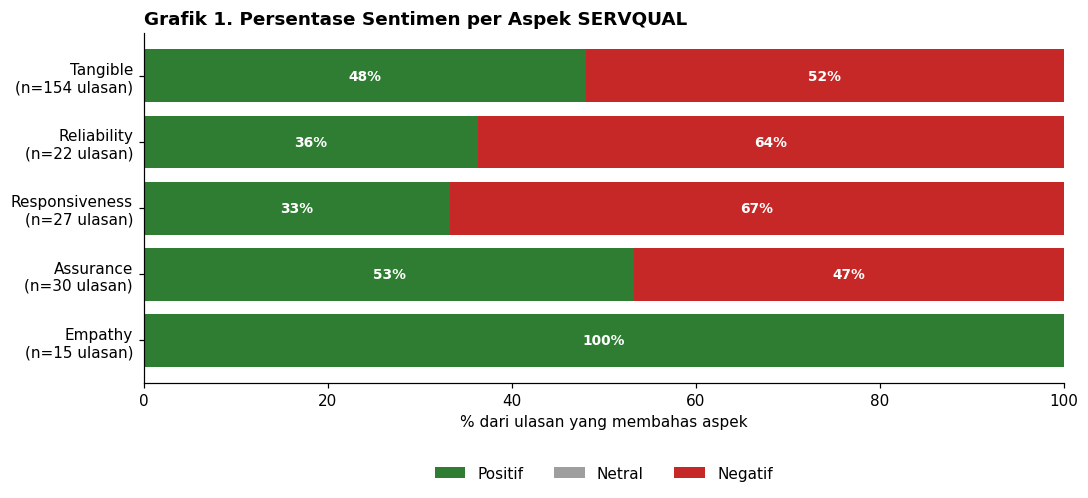

,Positif,Netral,Negatif,% Positif,% Negatif,% ulasan membahas
Tangible,74,0,80,48.1,51.9,82.4
Reliability,8,0,14,36.4,63.6,11.8
Responsiveness,9,0,18,33.3,66.7,14.4
Assurance,16,0,14,53.3,46.7,16.0
Empathy,15,0,0,100.0,0.0,8.0


In [ ]:
WARNA = {"Positif": "#2e7d32", "Netral": "#9e9e9e", "Negatif": "#c62828", "Tidak disebut": "#d0d7de"}

jumlah = pd.DataFrame({a: df_wide[a].value_counts() for a in ASPEK_VALID}).T.reindex(columns=SENTIMEN).fillna(0)
persen = jumlah.div(jumlah.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
kiri = np.zeros(len(persen))
for s in SENTIMEN:
    ax.barh(persen.index, persen[s], left=kiri, color=WARNA[s], label=s)
    for i, (v, l) in enumerate(zip(persen[s], kiri)):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", va="center", ha="center", color="white", fontsize=9, fontweight="bold")
    kiri += persen[s].values
ax.set_yticks(range(len(persen)))
ax.set_yticklabels([f"{a}\n(n={int(jumlah.loc[a].sum())} ulasan)" for a in persen.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dari ulasan yang membahas aspek")
ax.set_title("Grafik 1. Persentase Sentimen per Aspek SERVQUAL", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.32), frameon=False)
plt.tight_layout()
plt.savefig("grafik/1_persentase_sentimen_per_aspek.png", bbox_inches="tight")
plt.show()

display(jumlah.astype(int).assign(**{
    "% Positif": persen["Positif"].round(1), "% Negatif": persen["Negatif"].round(1),
    "% ulasan membahas": (jumlah.sum(axis=1) / len(df_wide) * 100).round(1)}))

### 4.2 Visualisasi silang: sentimen aspek × rating bintang

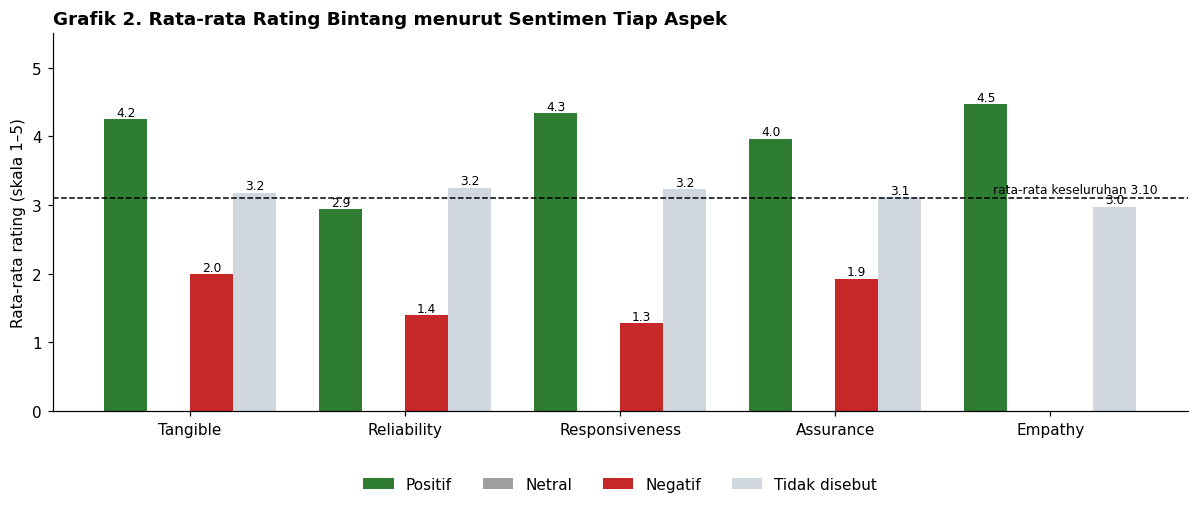

,Positif,Netral,Negatif,Tidak disebut
Tangible,4.25,NaN,1.99,3.18
Reliability,2.94,NaN,1.39,3.25
Responsiveness,4.33,NaN,1.28,3.23
Assurance,3.97,NaN,1.93,3.11
Empathy,4.47,NaN,NaN,2.98


In [ ]:
urutan = ["Positif", "Netral", "Negatif", "Tidak disebut"]
rata = pd.DataFrame({a: df_wide.groupby(a)["rating_5"].mean() for a in ASPEK_VALID}).T.reindex(columns=urutan)

fig, ax = plt.subplots(figsize=(11, 4.8))
lebar = 0.2
x = np.arange(len(ASPEK_VALID))
for j, s in enumerate(urutan):
    nilai = rata[s].values
    batang = ax.bar(x + (j - 1.5) * lebar, np.nan_to_num(nilai), lebar, color=WARNA[s], label=s)
    for b, v in zip(batang, nilai):
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.1f}", ha="center", fontsize=8)
rerata = df_wide["rating_5"].mean()
ax.axhline(rerata, ls="--", color="black", lw=1)
ax.text(len(ASPEK_VALID) - 0.5, rerata + 0.08, f"rata-rata keseluruhan {rerata:.2f}", ha="right", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ASPEK_VALID)
ax.set_ylim(0, 5.5)
ax.set_ylabel("Rata-rata rating (skala 1–5)")
ax.set_title("Grafik 2. Rata-rata Rating Bintang menurut Sentimen Tiap Aspek", loc="left", fontweight="bold")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.savefig("grafik/2_rating_x_sentimen_aspek.png", bbox_inches="tight")
plt.show()
display(rata.round(2))

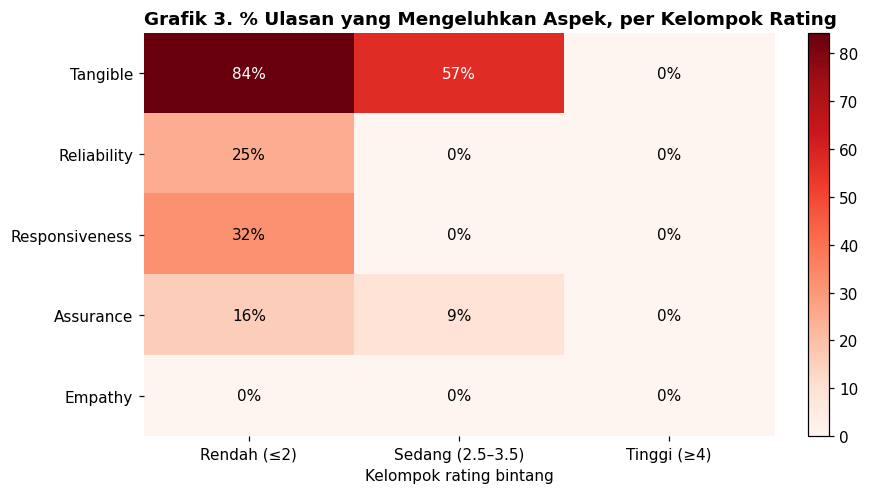

Jumlah ulasan per kelompok rating: {'Rendah (≤2)': 57, 'Sedang (2.5–3.5)': 56, 'Tinggi (≥4)': 74}


In [ ]:
per_kelompok = (keluhan.join(df_wide["kelompok_rating"])
                        .groupby("kelompok_rating", observed=False)[ASPEK_VALID].mean().T * 100)

fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(per_kelompok.values.astype(float), cmap="Reds", aspect="auto", vmin=0,
               vmax=max(1, np.nanmax(per_kelompok.values)))
ax.set_xticks(range(per_kelompok.shape[1]))
ax.set_xticklabels(per_kelompok.columns)
ax.set_yticks(range(per_kelompok.shape[0]))
ax.set_yticklabels(per_kelompok.index)
batas = np.nanmax(per_kelompok.values) * 0.6
for i in range(per_kelompok.shape[0]):
    for j in range(per_kelompok.shape[1]):
        v = per_kelompok.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=10, color="white" if v > batas else "black")
for sisi in ax.spines.values():
    sisi.set_visible(False)
ax.set_xlabel("Kelompok rating bintang")
ax.set_title("Grafik 3. % Ulasan yang Mengeluhkan Aspek, per Kelompok Rating", loc="left", fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.03)
plt.tight_layout()
plt.savefig("grafik/3_heatmap_keluhan_x_rating.png", bbox_inches="tight")
plt.show()
print("Jumlah ulasan per kelompok rating:", df_wide["kelompok_rating"].value_counts().sort_index().to_dict())

### 4.3 Korelasi aspek terhadap rating

Skor sentimen tiap ulasan per aspek (Positif = +1, Netral/Tidak disebut = 0, Negatif = −1) dikorelasikan dengan rating bintang menggunakan **korelasi Spearman**. Semakin tinggi nilainya, semakin kuat sentimen aspek tersebut "menggerakkan" rating. Tabel dampak menambahkan seberapa besar rating turun ketika aspek dikeluhkan.

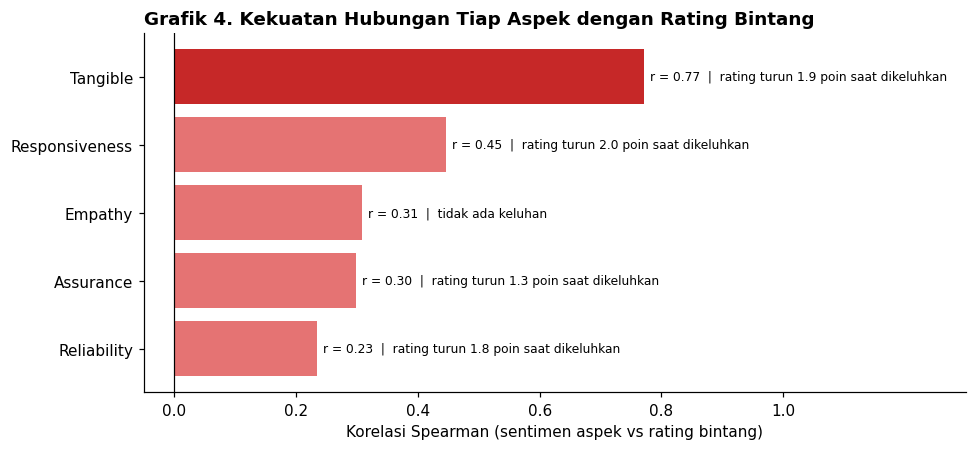

,korelasi_spearman,n_keluhan,pct_ulasan_mengeluhkan,rating_saat_dikeluhkan,rating_saat_tidak_dikeluhkan,penurunan_rating,skor_prioritas
Tangible,0.77,80,42.78,1.99,3.92,1.93,0.82
Responsiveness,0.45,18,9.63,1.28,3.29,2.01,0.19
Empathy,0.31,0,0.00,NaN,3.10,0.00,0.00
Assurance,0.30,14,7.49,1.93,3.19,1.26,0.09
Reliability,0.23,14,7.49,1.39,3.23,1.84,0.14


In [ ]:
PETA_SKOR = {"Positif": 1, "Netral": 0, "Tidak disebut": 0, "Negatif": -1}
skor_wide = df_wide[ASPEK_VALID].apply(lambda kolom: kolom.map(PETA_SKOR)).astype(float)
# Spearman = korelasi Pearson pada ranking
korelasi = pd.Series({a: skor_wide[a].rank().corr(df_wide["rating_5"].rank()) for a in ASPEK_VALID}).fillna(0)

dampak = pd.DataFrame({
    "korelasi_spearman": korelasi,
    "n_keluhan": keluhan.sum(),
    "pct_ulasan_mengeluhkan": keluhan.mean() * 100,
    "rating_saat_dikeluhkan": {a: df_wide.loc[keluhan[a], "rating_5"].mean() for a in ASPEK_VALID},
    "rating_saat_tidak_dikeluhkan": {a: df_wide.loc[~keluhan[a], "rating_5"].mean() for a in ASPEK_VALID},
})
dampak["penurunan_rating"] = (dampak["rating_saat_tidak_dikeluhkan"] - dampak["rating_saat_dikeluhkan"]).fillna(0)
dampak["skor_prioritas"] = dampak["pct_ulasan_mengeluhkan"] / 100 * dampak["penurunan_rating"]
dampak = dampak.sort_values("korelasi_spearman", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.2))
urut = dampak["korelasi_spearman"].sort_values()
batang = ax.barh(urut.index, urut.values, color=["#c62828" if v == urut.max() else "#e57373" for v in urut.values])
for b, (a, v) in zip(batang, urut.items()):
    info = (f"rating turun {dampak.loc[a, 'penurunan_rating']:.1f} poin saat dikeluhkan"
            if dampak.loc[a, "n_keluhan"] > 0 else "tidak ada keluhan")
    ax.text(max(v, 0) + 0.01, b.get_y() + b.get_height() / 2, f"r = {v:.2f}  |  {info}", va="center", fontsize=8)
ax.set_xlim(min(0, urut.min()) - 0.05, 1.3)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Korelasi Spearman (sentimen aspek vs rating bintang)")
ax.set_title("Grafik 4. Kekuatan Hubungan Tiap Aspek dengan Rating Bintang", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("grafik/4_korelasi_aspek_rating.png", bbox_inches="tight")
plt.show()
display(dampak.round(2))

In [ ]:
# Bukti keluhan & pujian dominan per aspek → dasar rekomendasi (Action)
def bukti_dominan(sentimen, n=3):
    return (df_long[df_long["sentimen"] == sentimen]
            .assign(bukti_ringkas=lambda d: d["bukti"].str.lower().str.strip(" .!"))
            .groupby(["aspek", "bukti_ringkas"]).size().rename("jumlah_ulasan").reset_index()
            .sort_values(["aspek", "jumlah_ulasan"], ascending=[True, False]).groupby("aspek").head(n))

print("KELUHAN dominan per aspek:")
display(bukti_dominan("Negatif"))
print("PUJIAN dominan per aspek:")
display(bukti_dominan("Positif"))

KELUHAN dominan per aspek:


,aspek,bukti_ringkas,jumlah_ulasan
0,Assurance,resepsionisnya jutek parah,7
2,Assurance,stafna kurang ramah pas di resto,5
1,Assurance,staff barely speaks english,2
4,Reliability,proses check in lama bgt nunggu hampir 2 jam,7
3,Reliability,ga sesuai foto,5
5,Reliability,the pictures are misleading,2
7,Responsiveness,pelayanan sangat buruk,10
6,Responsiveness,minta ganti tpi housekeeping lama,8
19,Tangible,parkiran sempit susah keluar masuk,10
23,Tangible,wifi aja sering putus2,10


PUJIAN dominan per aspek:


,aspek,bukti_ringkas,jumlah_ulasan
1,Assurance,staf ramah semua,14
0,Assurance,friendly staff,2
2,Empathy,karyawannya helpfull banget pas sy ketinggalan barang lgsg dihubungin,12
3,Empathy,staff went above and beyond,3
4,Reliability,check in cepet,8
5,Responsiveness,proses checkin juga sat set ga pake lama,9
6,Tangible,anak2 seneng bgt main di pool nya,15
8,Tangible,bersih dan nyaman,15
12,Tangible,"mantapppp nyaman banget, bersih",14


### 4.4 Executive Summary (B-I-A)

Sel berikut menyusun **draf otomatis** dari angka hasil analisis: **B**ackground (masalah), **I**nsight (temuan berbasis data dan korelasi aspek-rating), dan **A**ction (rekomendasi untuk aspek prioritas). Draf ini **wajib dibaca ulang dan disesuaikan** sebelum masuk laporan: cek angka dan bukti keluhan dominan di 4.3, lalu perhalus rekomendasinya. Panjangnya maksimal 2 paragraf.

In [ ]:
AKSI = {
    "Tangible": "lakukan audit kamar dan fasilitas berupa checklist kebersihan kamar, toilet, dan linen sebelum check-in, "
                "preventive maintenance AC dan water heater, peningkatan bandwidth wifi, serta jaga suhu dan "
                "ketersediaan buffet sampai jam sarapan berakhir",
    "Reliability": "tetapkan SLA check-in maksimal 15 menit (online pre-check-in dan tambahan petugas di jam sibuk) "
                   "dan samakan foto serta deskripsi kamar di OTA dengan kondisi aktual",
    "Responsiveness": "tetapkan SLA respons permintaan dan keluhan tamu (misalnya maksimal 30 menit) dengan sistem "
                      "pencatatan permintaan yang dipantau supervisor setiap shift",
    "Assurance": "adakan pelatihan service excellence dan bahasa Inggris dasar untuk seluruh staf front liner, "
                 "termasuk staf restoran, lalu evaluasi berkala melalui mystery guest",
    "Empathy": "jadikan inisiatif personal staf sebagai standar layanan melalui program apresiasi karyawan",
}
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli", "Agustus",
         "September", "Oktober", "November", "Desember"]

t_min, t_max = df_wide["tanggal"].min(), df_wide["tanggal"].max()
periode = (f"{BULAN[t_min.month - 1]}–{BULAN[t_max.month - 1]} {t_max.year}" if t_min.year == t_max.year
           else f"{BULAN[t_min.month - 1]} {t_min.year}–{BULAN[t_max.month - 1]} {t_max.year}")
pct_rendah = (df_wide["kelompok_rating"] == "Rendah (≤2)").mean() * 100

by_freq = dampak.sort_values("pct_ulasan_mengeluhkan", ascending=False)
by_kor = dampak.sort_values("korelasi_spearman", ascending=False)
prioritas = dampak[dampak["n_keluhan"] > 0].sort_values("skor_prioritas", ascending=False).index[:3].tolist()
a1, a2, k1 = by_freq.index[0], by_freq.index[1], by_kor.index[0]

def keluhan_utama(aspek):
    b = (df_long[(df_long["sentimen"] == "Negatif") & (df_long["aspek"] == aspek)]["bukti"]
         .str.lower().str.strip(" .!").value_counts())
    return b.index[0] if len(b) else "-"

dua_teratas = set(by_kor.index[:2])
banding = ("sejalan dengan" if {"Tangible", "Reliability"} <= dua_teratas
           else "sebagian sejalan dengan" if {"Tangible", "Reliability"} & dua_teratas else "berbeda dari")

paragraf_1 = (
    f"[Background] Rating klien di OTA stagnan tanpa kejelasan bagian layanan mana yang bermasalah. Analisis ABSA "
    f"berbasis SERVQUAL terhadap {len(df_wide)} ulasan Agoda, Booking.com, dan Traveloka ({periode}) menunjukkan "
    f"rata-rata rating {df_wide['rating_5'].mean():.2f}/5 dengan {pct_rendah:.0f}% ulasan berating rendah (≤2). "
    f"[Insight] Aspek yang paling sering dikeluhkan adalah {a1} ({by_freq.loc[a1, 'pct_ulasan_mengeluhkan']:.0f}% ulasan, "
    f"terutama \"{keluhan_utama(a1)}\") dan {a2} ({by_freq.loc[a2, 'pct_ulasan_mengeluhkan']:.0f}%, terutama "
    f"\"{keluhan_utama(a2)}\"). Aspek dengan hubungan terkuat terhadap rating adalah {k1} "
    f"(korelasi Spearman {by_kor.loc[k1, 'korelasi_spearman']:.2f}); saat {k1} dikeluhkan, rata-rata rating turun "
    f"dari {by_kor.loc[k1, 'rating_saat_tidak_dikeluhkan']:.1f} menjadi {by_kor.loc[k1, 'rating_saat_dikeluhkan']:.1f}. "
    f"Temuan ini {banding} Alaan (2016) yang menempatkan Tangible dan Reliability sebagai dimensi paling "
    f"berpengaruh terhadap kepuasan tamu hotel."
)

paragraf_2 = (
    "[Action] Berdasarkan frekuensi keluhan dan besarnya penurunan rating, prioritas perbaikan adalah: "
    + "; ".join(f"({i}) {a}: {AKSI[a]}" for i, a in enumerate(prioritas, 1))
    + ". Dampaknya dipantau dengan menjalankan ulang pipeline ABSA ini setiap bulan dan menargetkan penurunan "
      f"porsi ulasan yang mengeluhkan {prioritas[0]}, sehingga rating OTA dapat kembali naik."
)

print(paragraf_1, "\n")
print(paragraf_2)

[Background] Rating klien di OTA stagnan tanpa kejelasan bagian layanan mana yang bermasalah. Analisis ABSA berbasis SERVQUAL terhadap 187 ulasan Agoda, Booking.com, dan Traveloka (Maret–April 2026) menunjukkan rata-rata rating 3.10/5 dengan 30% ulasan berating rendah (≤2). [Insight] Aspek yang paling sering dikeluhkan adalah Tangible (43% ulasan, terutama "parkiran sempit susah keluar masuk") dan Responsiveness (10%, terutama "pelayanan sangat buruk"). Aspek dengan hubungan terkuat terhadap rating adalah Tangible (korelasi Spearman 0.77); saat Tangible dikeluhkan, rata-rata rating turun dari 3.9 menjadi 2.0. Temuan ini sebagian sejalan dengan Alaan (2016) yang menempatkan Tangible dan Reliability sebagai dimensi paling berpengaruh terhadap kepuasan tamu hotel. 

[Action] Berdasarkan frekuensi keluhan dan besarnya penurunan rating, prioritas perbaikan adalah: (1) Tangible: lakukan audit kamar dan fasilitas berupa checklist kebersihan kamar, toilet, dan linen sebelum check-in, preventiv

### 4.5 Export hasil

In [1]:
df_long.drop(columns=["kunci"]).to_csv("Final_ABSA_Hotel_per_temuan.csv", index=False, sep=";")
df_wide.to_csv("Final_ABSA_Hotel_per_ulasan.csv", sep=";")
dampak.round(3).to_csv("Ringkasan_Dampak_Aspek.csv", sep=";")
with open("Executive_Summary_BIA_draf.txt", "w", encoding="utf-8") as f:
    f.write(paragraf_1 + "\n\n" + paragraf_2)

import shutil
shutil.make_archive("grafik_absa_hotel", "zip", ".", "grafik")
print("Tersimpan: Final_ABSA_Hotel_per_temuan.csv, Final_ABSA_Hotel_per_ulasan.csv, Ringkasan_Dampak_Aspek.csv,")
print("           Executive_Summary_BIA_draf.txt, grafik_absa_hotel.zip")

try:
    from google.colab import files
    for nama in ["Final_ABSA_Hotel_per_ulasan.csv", "Final_ABSA_Hotel_per_temuan.csv", "grafik_absa_hotel.zip"]:
        files.download(nama)
except ImportError:
    pass

NameError: name 'df_long' is not defined

---
## Peta Notebook → Laporan PDF

| Bagian laporan (wajib) | Ambil dari |
|---|---|
| Identitas / Kelompok | Sel judul paling atas |
| Bukti Literatur (judul paper + 3–5 aspek) | Task 1 |
| Platform / Provider API LLM + screenshot interface | Task 2 (tabel provider) dan output sel 2.2. Screenshot **console.groq.com** atau **console.x.ai** (Playground/Dashboard) serta panel Colab Secrets, **tanpa menampilkan isi API key** |
| Teknik/metode prompt + alasannya | Task 3.1 (tabel) dan 3.2 (demo perbandingan) |
| Snippet kode & prompt | Sel prompt final (3.3), sel looping API (3.5), sel penggabungan ke DataFrame (3.6) |
| Visualisasi data | Grafik 1–4 di folder `grafik/` |
| Executive Summary (B-I-A, maks. 2 paragraf) | Draf di 4.4 (setelah disunting) |